# **YOLOV9**

In [ ]:
!nvidia-smi

Wed Apr  8 16:12:58 2026       
+-----------------------------------------------------------------------------------------+
| NVIDIA-SMI 580.82.07              Driver Version: 580.82.07      CUDA Version: 13.0     |
+-----------------------------------------+------------------------+----------------------+
| GPU  Name                 Persistence-M | Bus-Id          Disp.A | Volatile Uncorr. ECC |
| Fan  Temp   Perf          Pwr:Usage/Cap |           Memory-Usage | GPU-Util  Compute M. |
|                                         |                        |               MIG M. |
|=========================================+========================+======================|
|   0  Tesla T4                       Off |   00000000:00:04.0 Off |                    0 |
| N/A   44C    P8              9W /   70W |       0MiB /  15360MiB |      0%      Default |
|                                         |                        |                  N/A |
+-----------------------------------------+-----

In [ ]:
import os
HOME = os.getcwd()
print(HOME)

/content


In [ ]:
!pip install ultralytics -q

from IPython import display
import os

display.clear_output()

!yolo settings sync=False

import ultralytics
ultralytics.checks()

from ultralytics import YOLO

model = YOLO('yolov9c.pt')

print("YOLOv9 başarıyla yüklendi ve hazır!")

Ultralytics 8.4.35 🚀 Python-3.12.13 torch-2.10.0+cu128 CUDA:0 (Tesla T4, 14913MiB)
Setup complete ✅ (2 CPUs, 12.7 GB RAM, 43.4/112.6 GB disk)
YOLOv9 başarıyla yüklendi ve hazır!


In [ ]:
from IPython.display import display, Image

In [ ]:
!mkdir -p {HOME}/datasets
%cd {HOME}/datasets

/content/datasets


In [ ]:
!pip install roboflow

from roboflow import Roboflow
api_key = "YOUR_ROBOFLOW_API_KEY"
workspace_name = "YOUR_ROBOFLOW_WORKSPACE"
project_slug = "YOUR_PROJECT_SLUG"
if api_key == "YOUR_ROBOFLOW_API_KEY" or workspace_name == "YOUR_ROBOFLOW_WORKSPACE" or project_slug == "YOUR_PROJECT_SLUG":
    raise ValueError("Please add your Roboflow API key, workspace, and project slug before running this cell.")
rf = Roboflow(api_key=api_key)
project = rf.workspace(workspace_name).project(project_slug)
version = project.version(1)
dataset = version.download("yolov9")


loading Roboflow workspace...
loading Roboflow project...


In [ ]:
import zipfile
import os

zip_path = '/content/datasets/Skin-Cancer-1/roboflow.zip'
extract_path = '/content/datasets/Skin-Cancer-1/'

if os.path.exists(zip_path):
    with zipfile.ZipFile(zip_path, 'r') as zip_ref:
        zip_ref.extractall(extract_path)
    print("Dosyalar başarıyla çıkarıldı! ✅")
else:
    print("Hata: roboflow.zip bulunamadı. Lütfen 'ls /content/datasets/Skin-Cancer-1/' ile içeriği kontrol et.")

Dosyalar başarıyla çıkarıldı! ✅


In [ ]:
%cd {HOME}

!yolo task=detect mode=train model=yolov9c.pt data=/content/datasets/Skin-Cancer-1/data.yaml epochs=25 imgsz=800 batch=8 plots=True name=yolov9_skin_cancer

/content
Ultralytics 8.4.35 🚀 Python-3.12.13 torch-2.10.0+cu128 CUDA:0 (Tesla T4, 14913MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=8, bgr=0.0, box=7.5, cache=False, cfg=None, classes=None, close_mosaic=10, cls=0.5, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/content/datasets/Skin-Cancer-1/data.yaml, degrees=0.0, deterministic=True, device=None, dfl=1.5, dnn=False, dropout=0.0, dynamic=False, embed=None, end2end=None, epochs=25, erasing=0.4, exist_ok=False, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, half=False, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=800, int8=False, iou=0.7, keras=False, kobj=1.0, line_width=None, lr0=0.01, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model=yolov9c.pt, momentum=0.937, mosaic=1.0, multi_scale=0.0, name=yolov9_skin_cancer3, nbs=64, nms=False, opset=None, optimize=False, optimizer=auto, overlap_ma

In [ ]:
from ultralytics import YOLO
import os

all_folders = [os.path.join(f"{HOME}/runs/detect", d) for d in os.listdir(f"{HOME}/runs/detect") if os.path.isdir(os.path.join(f"{HOME}/runs/detect", d))]
latest_folder = max(all_folders, key=os.path.getmtime)

model_path = f"{latest_folder}/weights/best.pt"
model = YOLO(model_path)

print(f"Model yükleniyor: {model_path}")

results = model.val(data=f"{dataset.location}/data.yaml")

print(f"İşlem tamam! Şimdi şu klasörü kontrol et: {latest_folder}")

Model yükleniyor: /content/runs/detect/yolov9_skin_cancer3/weights/best.pt
Ultralytics 8.4.35 🚀 Python-3.12.13 torch-2.10.0+cu128 CUDA:0 (Tesla T4, 14913MiB)
YOLOv9c summary (fused): 156 layers, 25,320,790 parameters, 0 gradients, 102.3 GFLOPs
val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 324.9±136.8 MB/s, size: 6.7 KB)
val: Scanning /content/datasets/Skin-Cancer-1/valid/labels.cache... 400 images, 0 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 400/400 64.5Mit/s 0.0s
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 25/25 1.2it/s 20.5s
                   all        400        407      0.732      0.893      0.868      0.693
                Benign        200        206      0.743      0.883      0.916      0.745
                Cancer        200        201      0.721      0.902      0.821       0.64
Speed: 2.9ms preprocess, 44.0ms inference, 0.0ms loss, 0.8ms postprocess per image
Results saved to /content/runs/detect/val
İşlem t

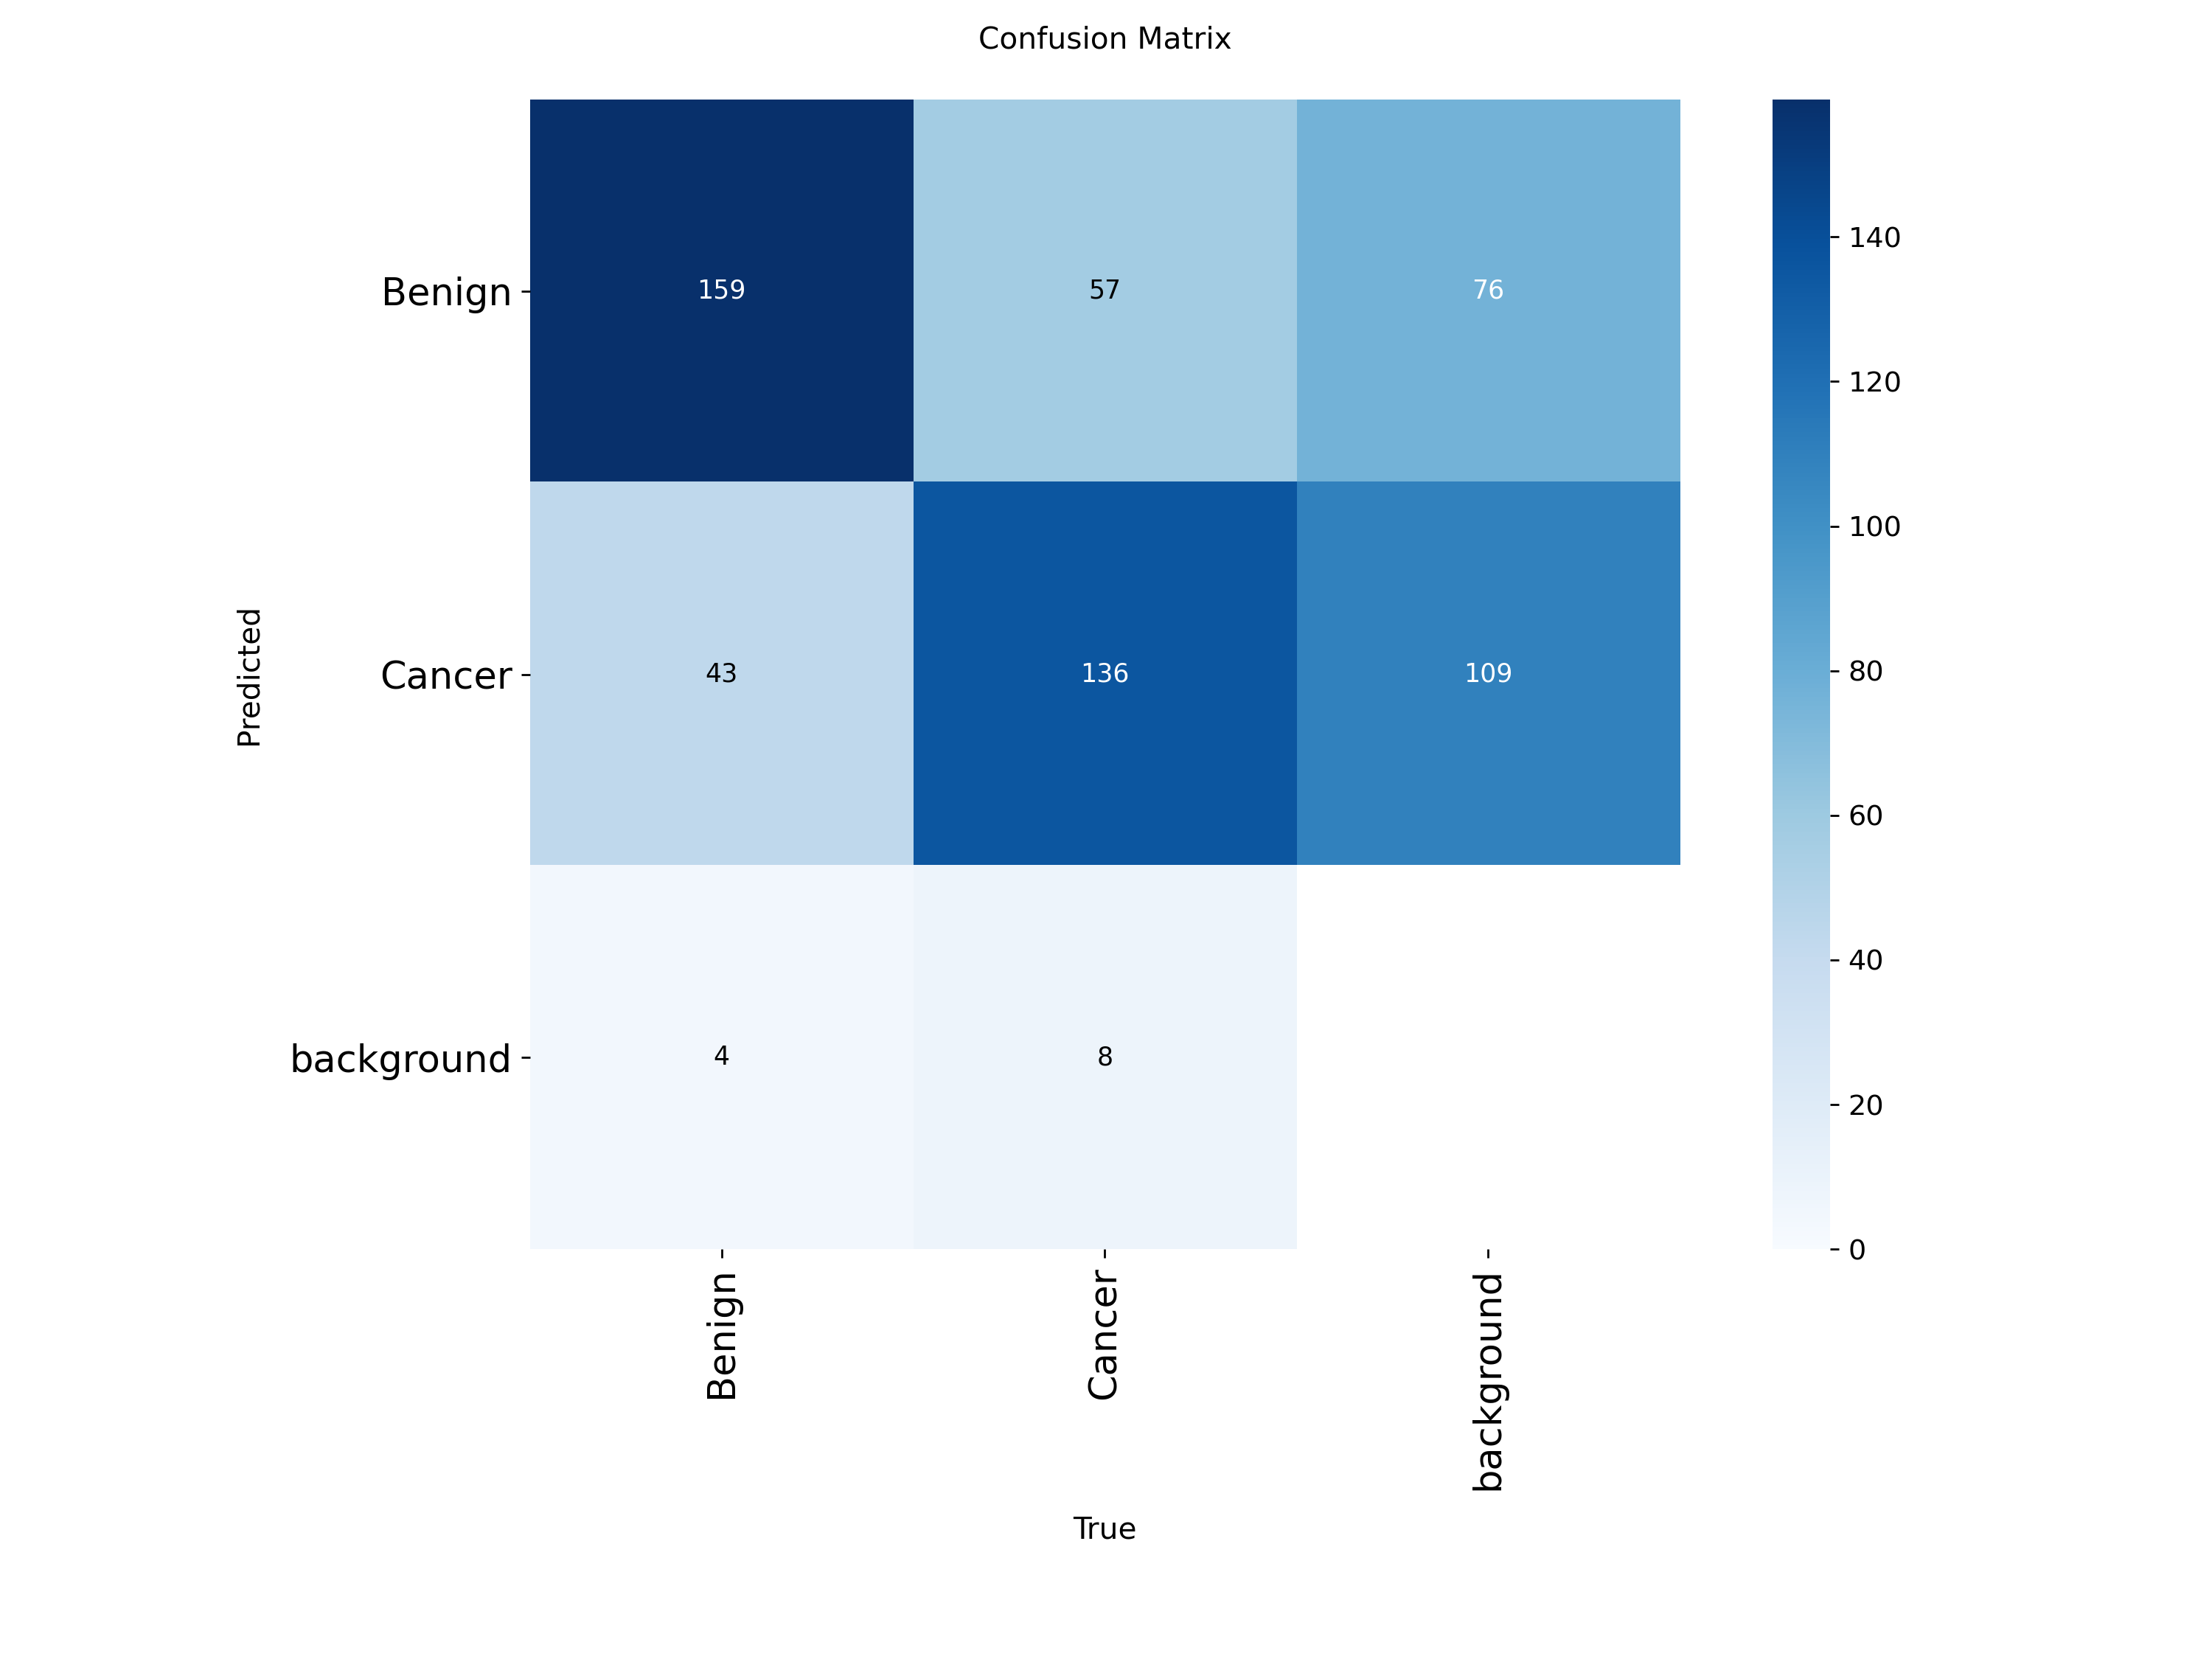

In [ ]:
from IPython.display import Image, display
display(Image(filename=f"{latest_folder}/confusion_matrix.png", width=600))

/content


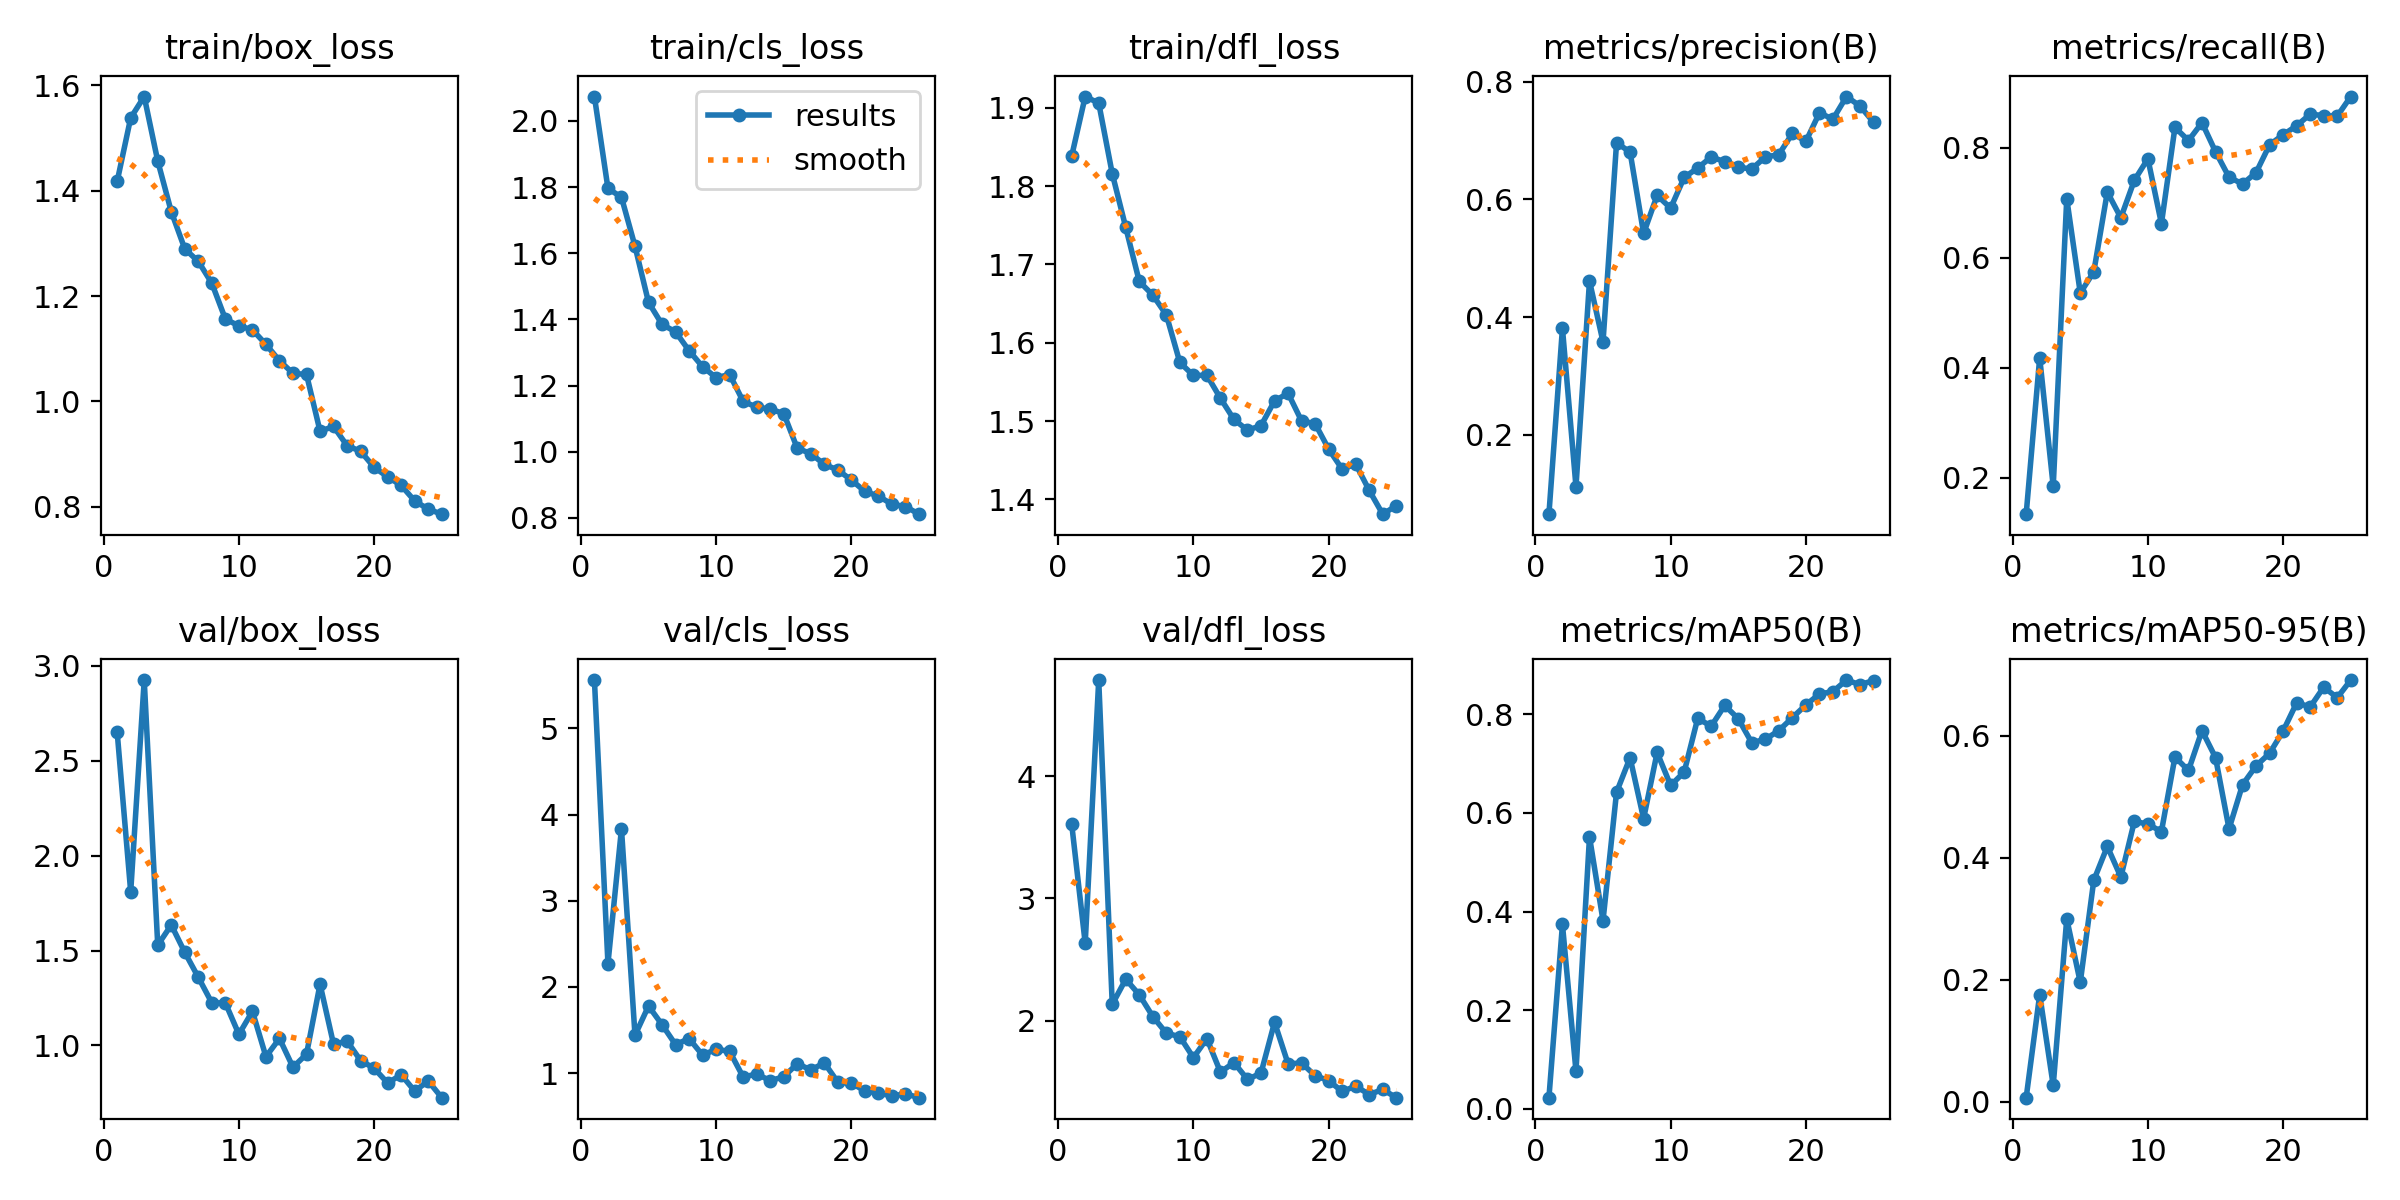

In [ ]:
%cd {HOME}
from IPython.display import Image, display

train_results_folder = f'{HOME}/runs/detect/yolov9_skin_cancer3'
display(Image(filename=f'{train_results_folder}/results.png', width=600))

/content


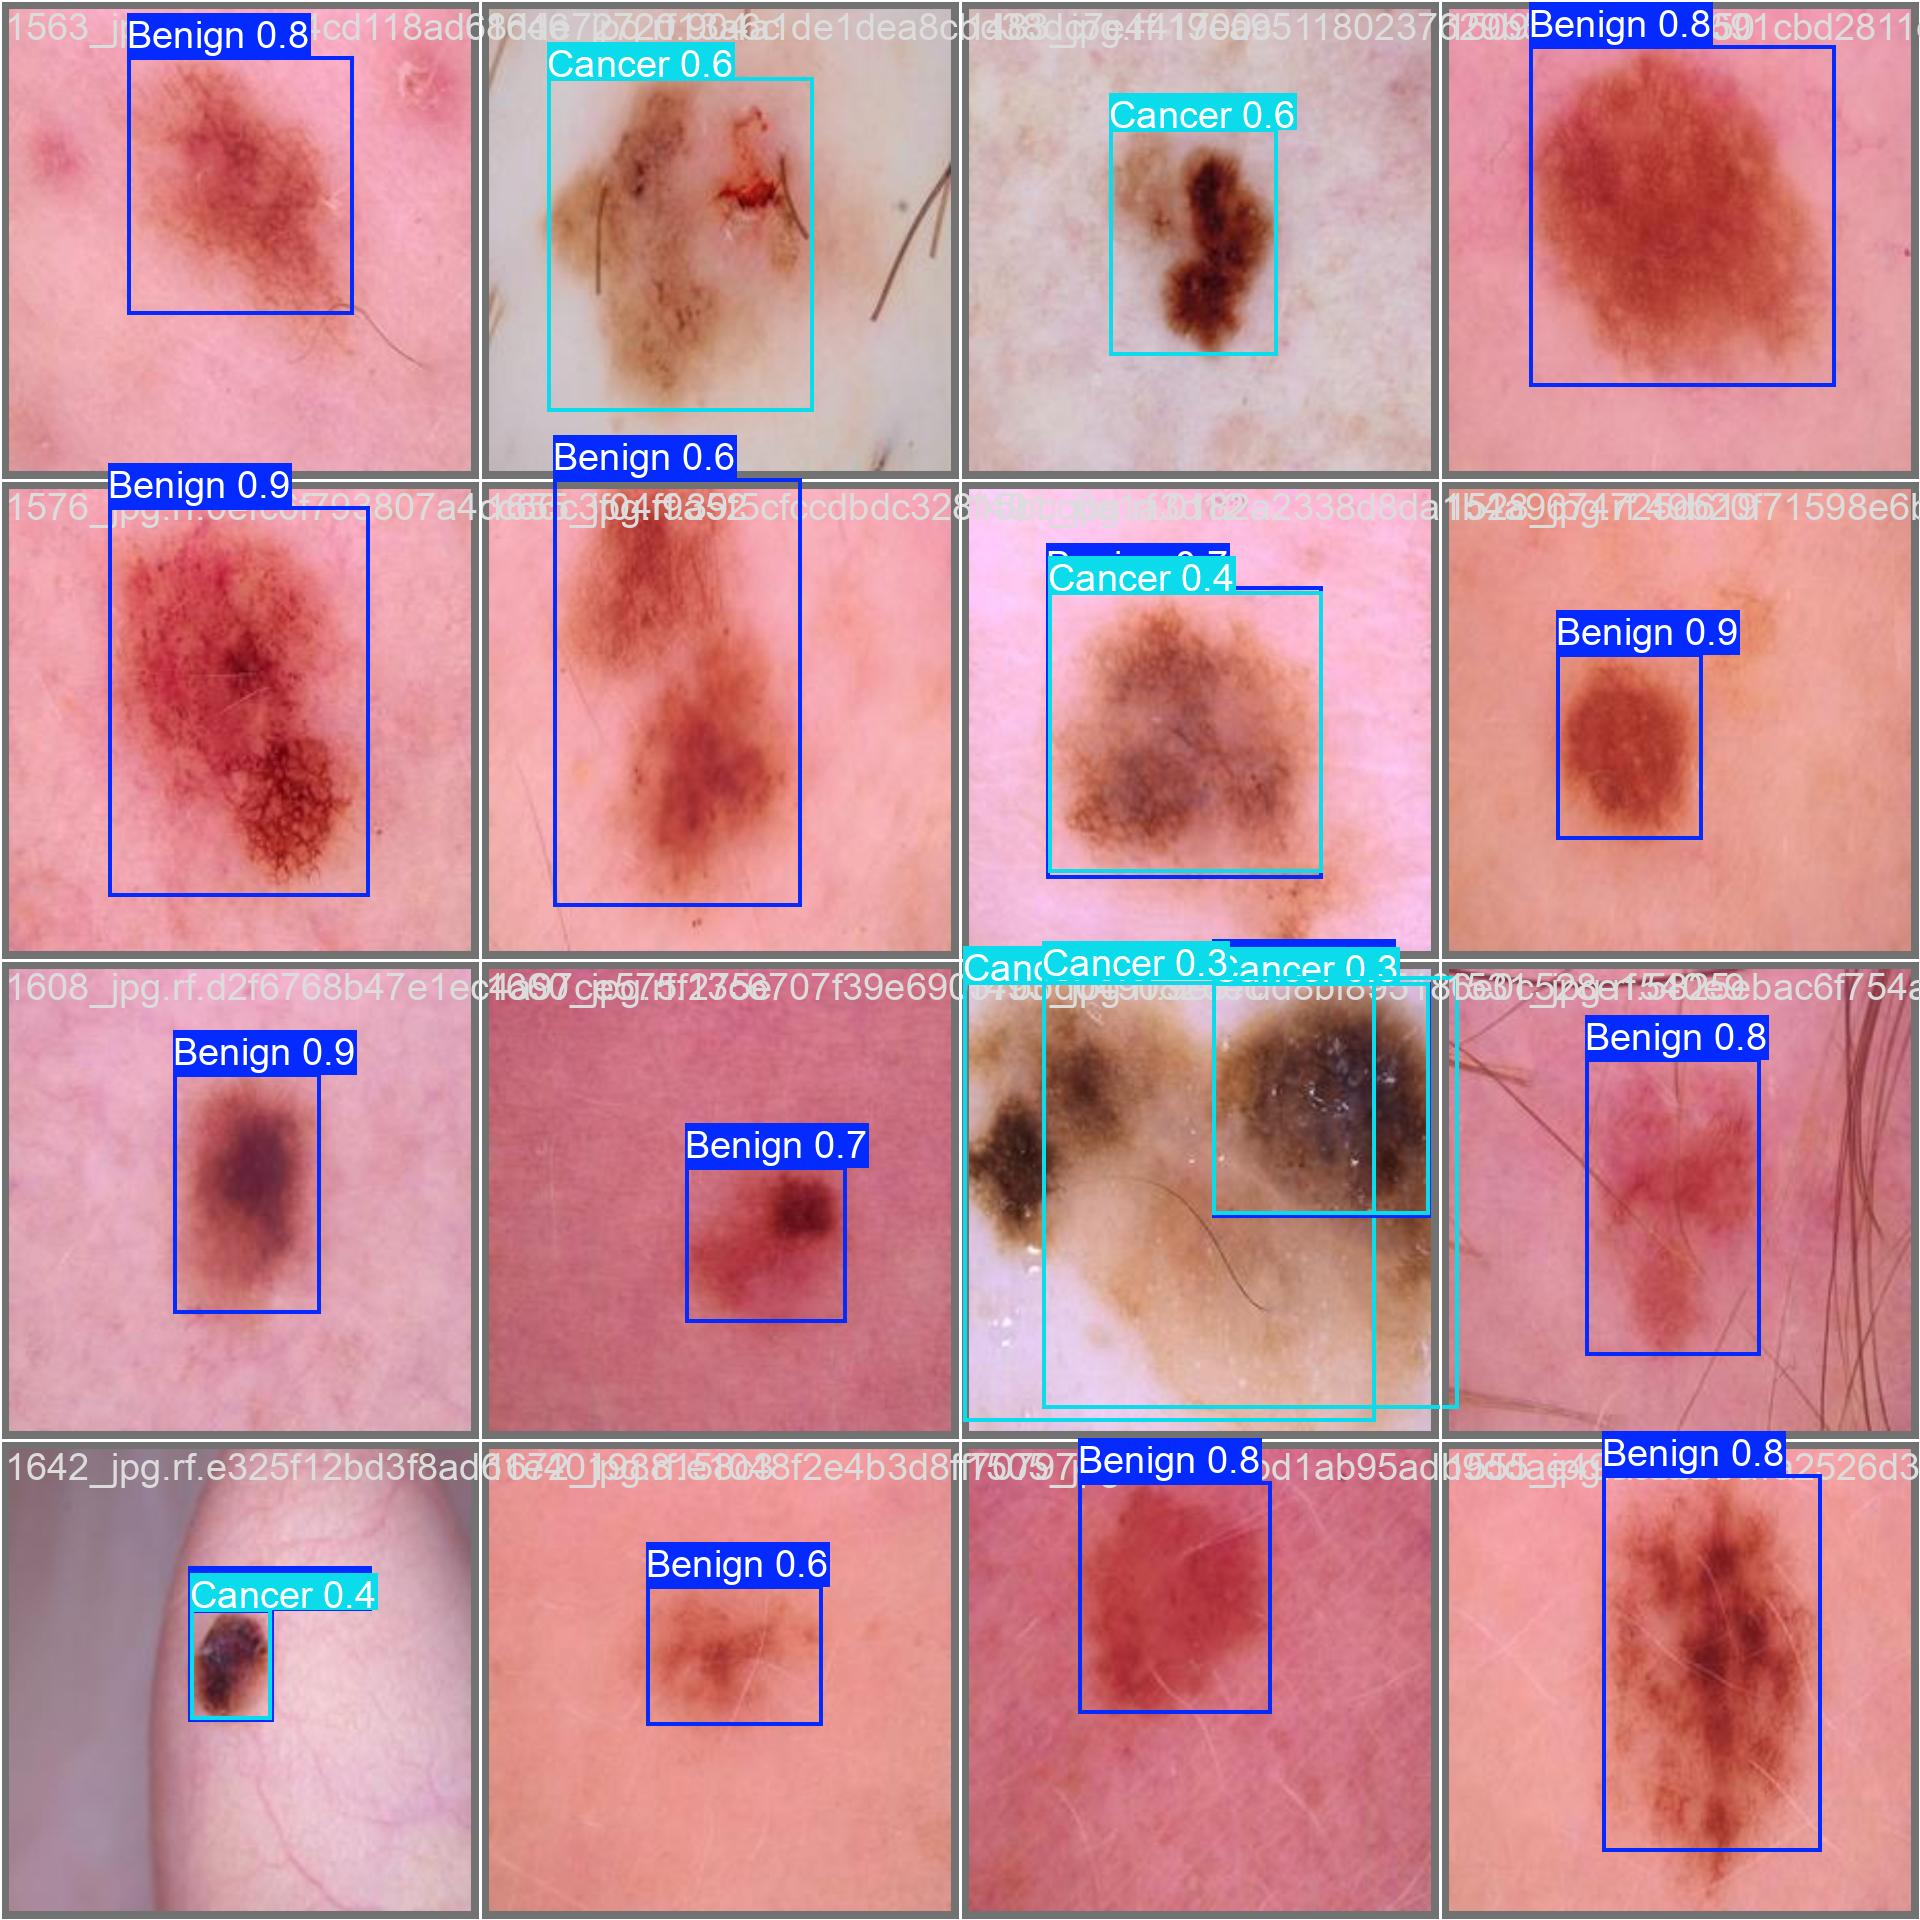

In [ ]:
%cd {HOME}
from IPython.display import Image
Image(filename=f'{latest_folder}/val_batch0_pred.jpg', width=600)

In [ ]:
%cd {HOME}

!yolo task=detect mode=val model={train_results_folder}/weights/best.pt data={dataset.location}/data.yaml

/content
Ultralytics 8.4.35 🚀 Python-3.12.13 torch-2.10.0+cu128 CUDA:0 (Tesla T4, 14913MiB)
YOLOv9c summary (fused): 156 layers, 25,320,790 parameters, 0 gradients, 102.3 GFLOPs
val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 409.8±157.7 MB/s, size: 6.7 KB)
val: Scanning /content/datasets/Skin-Cancer-1/valid/labels.cache... 400 images, 0 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 400/400 69.9Mit/s 0.0s
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 25/25 1.1it/s 23.2s
                   all        400        407      0.732      0.893      0.868      0.693
                Benign        200        206      0.743      0.883      0.916      0.745
                Cancer        200        201      0.721      0.902      0.821       0.64
Speed: 3.0ms preprocess, 51.0ms inference, 0.0ms loss, 0.7ms postprocess per image
Results saved to /content/runs/detect/val2
💡 Learn more at https://docs.ultralytics.com/modes/val


In [ ]:
import pandas as pd


names = list(results.names.values())

p_list = results.box.p.tolist()       # Precision listesi
r_list = results.box.r.tolist()       # Recall listesi
ap50_list = results.box.ap50.tolist() # mAP50 listesi
ap_list = results.box.ap.tolist()     # mAP50-95 listesi

metrics_data = []
for i, name in enumerate(names):
    metrics_data.append({
        "Class": name,
        "Precision": round(p_list[i], 3),
        "Recall": round(r_list[i], 3),
        "mAP@.5": round(ap50_list[i], 3),
        "mAP@.5:.95": round(ap_list[i], 3)
    })

all_stats = pd.DataFrame([{
    "Class": "all",
    "Precision": round(results.results_dict['metrics/precision(B)'], 3),
    "Recall": round(results.results_dict['metrics/recall(B)'], 3),
    "mAP@.5": round(results.results_dict['metrics/mAP50(B)'], 3),
    "mAP@.5:.95": round(results.results_dict['metrics/mAP50-95(B)'], 3)
}])

df_classes = pd.DataFrame(metrics_data)
final_table = pd.concat([all_stats, df_classes], ignore_index=True)

display(final_table)

,Class,Precision,Recall,mAP@.5,mAP@.5:.95
0,all,0.732,0.893,0.868,0.693
1,Benign,0.743,0.883,0.916,0.745
2,Cancer,0.721,0.902,0.821,0.640


In [ ]:
%cd {HOME}
!yolo task=detect mode=predict model={train_results_folder}/weights/best.pt conf=0.25 source={dataset.location}/test/images save=True

/content
Ultralytics 8.4.35 🚀 Python-3.12.13 torch-2.10.0+cu128 CUDA:0 (Tesla T4, 14913MiB)
YOLOv9c summary (fused): 156 layers, 25,320,790 parameters, 0 gradients, 102.3 GFLOPs

image 1/199 /content/datasets/Skin-Cancer-1/test/images/0013_jpg.rf.8a3791653d30332040cb5f9b7203f234.jpg: 800x800 1 Cancer, 70.3ms
image 2/199 /content/datasets/Skin-Cancer-1/test/images/0014_jpg.rf.9ddcdd6dd784f88b6fecdfe2b8275999.jpg: 800x800 1 Benign, 72.5ms
image 3/199 /content/datasets/Skin-Cancer-1/test/images/0022_jpg.rf.1fb84d65733e49c1699f6a2a01a96258.jpg: 800x800 1 Cancer, 59.7ms
image 4/199 /content/datasets/Skin-Cancer-1/test/images/0026_jpg.rf.25cf54aaf5e74585aa228063e043d2eb.jpg: 800x800 3 Cancers, 54.6ms
image 5/199 /content/datasets/Skin-Cancer-1/test/images/0027_jpg.rf.1a9aaed8ac34b1c4480e66bcd75d6f71.jpg: 800x800 1 Cancer, 54.7ms
image 6/199 /content/datasets/Skin-Cancer-1/test/images/0028_jpg.rf.182f1063c261a13363c4c0c46e8bcddd.jpg: 800x800 1 Benign, 2 Cancers, 51.9ms
image 7/199 /content/da

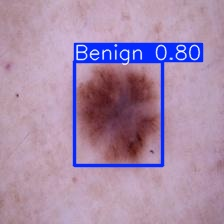

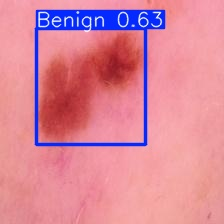

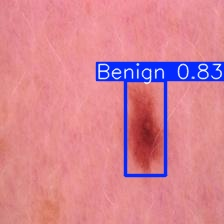

In [ ]:
import glob
from IPython.display import Image, display

base_path = '/content/runs/detect/'

subfolders = [os.path.join(base_path, d) for d in os.listdir(base_path)
              if os.path.isdir(os.path.join(base_path, d)) and d.startswith('predict')]

latest_folder = max(subfolders, key=os.path.getmtime)

image_paths = glob.glob(f'{latest_folder}/*.jpg')[:3]

for image_path in image_paths:
    display(Image(filename=image_path, width=600))
    print("\n")